# Assigning atoms to sites: the Hungarian algorithm, the exponent and the crossings

**Question:** How are loaded atoms assigned to the empty sites of a target block so that the block ends defect-free and the straight paths of the atoms do not cross?

- Level: 2, the method in practice.
- Prerequisites: `03-gerchberg-saxton/02-weights-for-uniformity`, because the sequence that follows is built from weighted GS holograms.
- Reading time: about 25 minutes. The notebook runs in about 30 seconds.

## Objectives

In a tweezer array the atoms load at random: each site holds an atom with a probability near one half, and a quantum computer or a simulator needs a block of sites that is all filled. The remedy is to read which sites are loaded, and to move the atoms from the surplus sites to the empty ones with the same traps that hold them. Deciding who goes where is the first half of that sort, and it needs no light at all. By the end you can:

- state the assignment as a minimum-cost matching, and say what the exponent of the cost changes;
- count the pairs of straight paths that cross, and read a table that compares exponents;
- read what M16 builds from the same assignment: the number of steps and of moving traps;
- say what the sort guarantees, and which of its guarantees depend on the loading that was drawn.

The notebook `07-feedback-and-dynamics/04-moving-atoms-by-linear-phase-interpolation` takes the second half, the light that moves the atoms.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.control import m16_rearrangement
from pipeline.model.holo.methods.control.m16_rearrangement import assign, count_crossings

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C10 of `data/examples/cases.json`: a 10 x 10 array of sites with a spacing of about 8 focal bins, a loading probability of 0.55 and a block of 36 target sites in the middle.

- Owner: this repository; the case is synthetic, and the loading is drawn from the portable generator with the seed of the record.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C10 (the `rearrangement` block carries the loading probability, the target ids and the exponent).

In [2]:
# case C10: a 10 x 10 site array, loaded at random, and a 6 x 6 block to be filled
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded = random_loading(rec)
wanted = rec["rearrangement"]["target_ids"]
empty = sorted(set(wanted) - set(loaded))
surplus = sorted(set(loaded) - set(wanted))
print(rec["case_id"], "|", len(sites), "sites | loading probability", rec["rearrangement"]["loading_p"])
print(f"loaded atoms: {len(loaded)} | target sites: {len(wanted)} | "
      f"empty target sites: {len(empty)} | surplus atoms: {len(surplus)}")

C10_rearrangement | 100 sites | loading probability 0.55
loaded atoms: 52 | target sites: 36 | empty target sites: 16 | surplus atoms: 32


The loading is one uniform number per site against the probability, so it is the same on every run. The figure shows which sites hold an atom and which of the 36 target sites are empty.

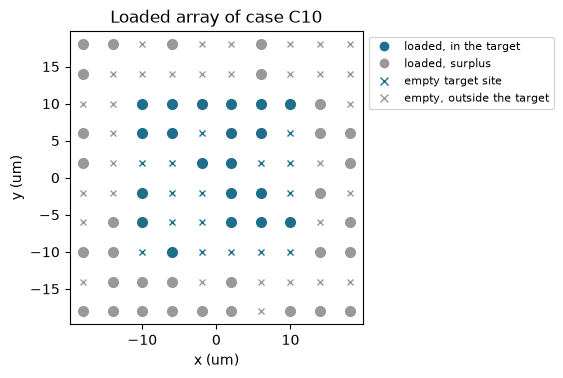

In [3]:
# the sites: loaded or empty, inside or outside the target block
xy = {i: (t["x_um"], t["y_um"]) for i, t in sites.items()}
fig, ax = plt.subplots(figsize=(5.4, 5.0))
for i, (x, y) in xy.items():
    inside, full = i in wanted, i in loaded
    ax.plot(x, y, "o" if full else "x", color="#1f6f8b" if inside else "#999999", markersize=7 if full else 5)
ax.plot([], [], "o", color="#1f6f8b", label="loaded, in the target")
ax.plot([], [], "o", color="#999999", label="loaded, surplus")
ax.plot([], [], "x", color="#1f6f8b", label="empty target site")
ax.plot([], [], "x", color="#999999", label="empty, outside the target")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("Loaded array of case C10")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

The draw gives 52 loaded atoms of the 100 sites, 36 target sites of which 16 are empty, and 32 surplus atoms outside the block. There are twice as many surplus atoms as holes, so a defect-free block is possible, and the question is only which 16 of the 32 go where; if the loading had left fewer atoms than holes, no assignment could fill the block, and the method refuses a case with fewer atoms than targets. The 20 blue circles inside the block are atoms already in place: they need not move, and they are part of the assignment, with a path of length zero. It also shows that the surplus atoms are spread over the rim, so the distances to the holes range from one site to several.

## Method

### Step 1: who goes where

The Hungarian algorithm (Kuhn and Munkres) finds the matching of the target sites to distinct atoms that minimises a total cost. For rearrangement, Lee, Kim and Ahn (2017) use $C(f) = \sum_i d_{i,f(i)}^{\alpha}$ with $d$ the distance between target $t_i$ and atom $a_{f(i)}$. With $\alpha = 1$ the cost is the total path length, and the optimum may send one atom far if that saves two short moves elsewhere. A larger $\alpha$ penalises long moves more than several short ones, which spreads the work, and the authors show that for a square lattice and $\alpha$ above about 1.12 the straight paths of the atoms do not trespass on each other. The sum runs over all 36 targets and 52 atoms, so an atom already in the block can be matched to its own site at zero cost. The cell computes the assignment for six exponents and reports, in focal bins, the total path, the longest move, the number of atoms that move and the number of pairs of straight paths that cross or overlap.

In [4]:
# the assignment for several exponents alpha of the cost d^alpha, in focal bins: path length, longest move,
# crossings
bin_m = focal_bin_m(setup)
atoms_bins = np.array([[xy[i][0], xy[i][1]] for i in loaded]) * 1e-6 / bin_m
targets_bins = np.array([[xy[i][0], xy[i][1]] for i in wanted]) * 1e-6 / bin_m
plans = {}
for alpha in (0.5, 1.0, 1.2, 1.5, 2.0, 3.0):
    chosen = assign(targets_bins, atoms_bins, alpha)
    starts = atoms_bins[chosen]
    length = np.hypot(*(starts - targets_bins).T)
    plans[alpha] = (starts, length, count_crossings(starts, targets_bins))
    print(f"alpha {alpha:3.1f}: total path {length.sum():6.1f} bins | longest move "
          f"{length.max():5.1f} bins | atoms that move {int((length > 1e-9).sum()):2d} | "
          f"crossing pairs {plans[alpha][2]}")

alpha 0.5: total path  264.1 bins | longest move  33.1 bins | atoms that move 16 | crossing pairs 1
alpha 1.0: total path  261.9 bins | longest move  29.0 bins | atoms that move 16 | crossing pairs 0
alpha 1.2: total path  267.1 bins | longest move  18.0 bins | atoms that move 21 | crossing pairs 0
alpha 1.5: total path  276.1 bins | longest move  18.0 bins | atoms that move 24 | crossing pairs 1
alpha 2.0: total path  293.6 bins | longest move  16.1 bins | atoms that move 27 | crossing pairs 0
alpha 3.0: total path  307.7 bins | longest move  16.1 bins | atoms that move 30 | crossing pairs 0


The table has the trade-off that the exponent controls. From $\alpha = 1.0$ to $\alpha = 1.2$ the longest move falls from 29.0 to 18.0 bins, nearly a site and a half shorter in a block whose sites are 8 bins apart, while the total path grows from 261.9 to 267.1 and the number of atoms that move from 16 to 21. Beyond 1.2 the longest move reaches a floor of 16.1 bins and the cost keeps rising: 276.1 bins at 1.5, 307.7 at 3.0, with 30 atoms in motion. The crossing count does not follow the exponent monotonically: 1 pair at 0.5, none at 1.0 and 1.2, 1 pair at 1.5, none at 2.0 and 3.0. The next figure draws the moves of two of the exponents, 1.0 and 1.5.

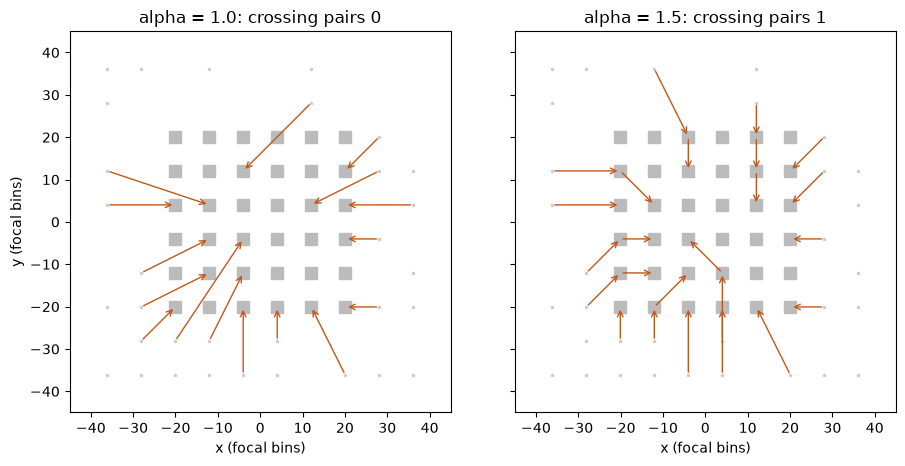

In [5]:
# the moves for alpha = 1.0 and alpha = 1.5: each arrow runs from an atom to the target site it fills
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6), sharey=True)
for ax, alpha in zip(axes, (1.0, 1.5)):
    starts, length, crossings = plans[alpha]
    ax.plot(*atoms_bins.T, ".", color="#cccccc", markersize=3)
    ax.plot(*targets_bins.T, "s", color="#bbbbbb", markersize=9)
    for s, e, d in zip(starts, targets_bins, length):
        if d > 1e-9:
            ax.annotate("", xy=e, xytext=s, arrowprops={"arrowstyle": "->", "color": "#c2571a", "linewidth": 1.0})
    ax.set_title(f"alpha = {alpha}: crossing pairs {crossings}")
    ax.set_xlabel("x (focal bins)")
    ax.set_xlim(-45, 45)
    ax.set_ylim(-45, 45)
    ax.set_aspect("equal")
axes[0].set_ylabel("y (focal bins)")
plt.tight_layout()
plt.show()

With $\alpha = 1.0$ a few atoms travel far, the arrows that cross most of the picture, and the rest stay put. With $\alpha = 1.5$ more atoms move and the moves are shorter and more local, each filling a hole in its neighbourhood. This is what the numbers said, and it matters for the next step, because the number of steps of the sequence is set by the longest move. The figure does not show the crossing pair of the $\alpha = 1.5$ plan, which is one pair among 276 bins of paths and is not visible at this size. A crossing of two straight paths is not a collision by itself: the atoms move in parallel and at the same fractional speed, so they meet only if they are at the crossing at the same time. The count is a conservative flag, as the pipeline defines it, and it is the quantity to set against the guarantee of the paper for a square lattice. For this loading, with 32 surplus atoms and a block in the middle, the exponent of 1.5 does not give zero: one pair.

### Step 2: what M16 builds from the assignment

M16 is the method of the product that runs the Hungarian assignment and then builds the holograms. Its plan is the same one the table gives: it reads the atoms and the target sites, assigns with the exponent it is given, and sets the number of steps from the longest move, $S = \lceil d_\text{max} / s_\text{max} \rceil$ with a step $s_\text{max}$ of two bins. Running it with a small budget of 8 iterations is enough to read the plan, because the plan does not depend on the light. The cell runs it for the exponent 1.0.

In [6]:
# M16 on the same sort with exponent 1.0: the plan it builds from the same atoms and targets
atoms = build.trapset_of([sites[i] for i in loaded])
goal = Target.from_traps(build.trapset_of([sites[i] for i in wanted]))
plan = {1.0: m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=1.0)}
print(f"alpha 1.0: {plan[1.0].meta['n_steps']} steps | {int(plan[1.0].meta['moved'].sum())} moving traps | "
      f"crossings {plan[1.0].meta['crossings']}")

alpha 1.0: 15 steps | 16 moving traps | crossings 0


With the exponent 1.0 the sort takes 15 steps, because its longest move is 29.0 bins, and moves 16 traps, with no crossing pair, in agreement with the table. The same plan for the exponent of Lee, Kim and Ahn follows.

In [7]:
# the same plan with exponent 1.5
plan[1.5] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=1.5)
print(f"alpha 1.5: {plan[1.5].meta['n_steps']} steps | {int(plan[1.5].meta['moved'].sum())} moving traps | "
      f"crossings {plan[1.5].meta['crossings']}")

alpha 1.5: 9 steps | 24 moving traps | crossings 1


The exponent 1.5 needs 9 steps and moves 24 traps, and the plan holds one crossing pair, as the table said. The next two cells run the exponents 2.0 and 3.0.

In [8]:
# the same plan with exponent 2.0
plan[2.0] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=2.0)
print(f"alpha 2.0: {plan[2.0].meta['n_steps']} steps | {int(plan[2.0].meta['moved'].sum())} moving traps | "
      f"crossings {plan[2.0].meta['crossings']}")

alpha 2.0: 9 steps | 27 moving traps | crossings 0


The exponent 2.0 also takes 9 steps, moves 27 traps, and has no crossing pair.

In [9]:
# the same plan with exponent 3.0
plan[3.0] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=3.0)
print(f"alpha 3.0: {plan[3.0].meta['n_steps']} steps | {int(plan[3.0].meta['moved'].sum())} moving traps | "
      f"crossings {plan[3.0].meta['crossings']}")

alpha 3.0: 9 steps | 30 moving traps | crossings 0


At the exponent 3.0 the plan moves 30 traps in 9 steps and has no crossing. The number of steps falls from 15 at the exponent 1.0 to 9 at every exponent from 1.5 on, because the longest move falls from 29.0 to 18.0 and 16.1 bins and the step is two bins. Fewer steps mean fewer holograms to display, and more moving traps mean more light in motion that has to stay bright. A sort is therefore a choice between a long sequence with few traps moving and a short one with many, and the exponent is the knob. The plan does not say how bright the traps stay while they move, which the next notebook of the topic measures, nor how the choice would change for another loading: this one draw has 52 atoms for 36 targets, and a loading near the minimum of 36 would leave the assignment with no freedom.

## Results

**Answer:** Atoms are assigned by the Hungarian algorithm, which minimises the sum of the distances raised to an exponent $\alpha$, and the exponent does not by itself remove the crossings. On case C10 a draw of 52 loaded atoms leaves 16 of the 36 target sites empty and 32 atoms surplus, so the block can be filled completely. With $\alpha = 1.0$ the total path is 261.9 bins, the longest move 29.0 bins, 16 atoms move and no pair of paths crosses; with $\alpha = 1.5$ the total is 276.1, the longest move 18.0, 24 atoms move and one pair crosses. Over six exponents the crossing count is 1, 0, 0, 1, 0 and 0 for $\alpha$ = 0.5, 1.0, 1.2, 1.5, 2.0 and 3.0, so the sort has at most one crossing pair here but the exponent that the paper recommends is not the one with none. M16 turns the plan into 15 steps at $\alpha = 1.0$ and 9 steps from 1.5 on.

What the notebook does not show is the sort over many loadings, or the light that moves the atoms.

## Summary

- Rearrangement is a minimum-cost matching of target sites to loaded atoms, solved by the Hungarian algorithm on the cost $d^\alpha$.
- A larger exponent shortens the longest move (29.0 bins at $\alpha = 1.0$, 18.0 at 1.2) at the price of a longer total path and more atoms in motion.
- The count of crossing pairs is not monotone in the exponent; $\alpha = 1.5$ leaves one pair on this loading.
- M16 sets the number of steps from the longest move: 15 at $\alpha = 1.0$, 9 from 1.5 on.

## References

- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391